# NUTDTS 816 Time Series Analysis
## Lab 0: Familiarisation (26 August 2026)

Goals: confirm Colab works, load a series with a DatetimeIndex, make a plot, save the notebook to your GitHub repository.

1. File > Save a copy in Drive.
2. Run the setup cell.
3. Run the data cell and the plot cell; change the plot to the log scale and run again.
4. Create a public GitHub repository named `nutdts816-<surname>`; File > Save a copy in GitHub.

In [1]:
# ---- Setup: run once per Colab session ----
# 1. Install the course libraries (about two minutes the first time)
!pip install -q statsmodels pmdarima statsforecast neuralforecast lightgbm arch plotly

# 2. Fetch the course data module and data snapshots from the course repository.
#    Replace REPO with your fork or the official course repository URL.
REPO = "https://github.com/toadesina/NUTDTS816_Course_Repository/raw/main/"
import urllib.request, os
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(f"{REPO}/src/tsdata.py", "tsdata.py")
DATA_FILES = ["nigeria_cpi", "nigeria_fx", "nigeria_grid", "nigeria_malaria", "nigeria_rainfall", "bonny_light", "daily_demand",
              "airpassengers", "a10", "h02", "ausbeer", "elecequip", "usmelec", "goog", "nile", "austourists", "oil", "dax", "uschange", "elecdemand"]
for f in DATA_FILES:
    urllib.request.urlretrieve(f"{REPO}/data/{f}.csv", f"data/{f}.csv")

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
import tsdata
print("Setup complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.3/331.3 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
ap = tsdata.airpassengers()
print(type(ap), ap.index.freq)
ap.head()

<class 'pandas.core.series.Series'> <MonthBegin>


,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


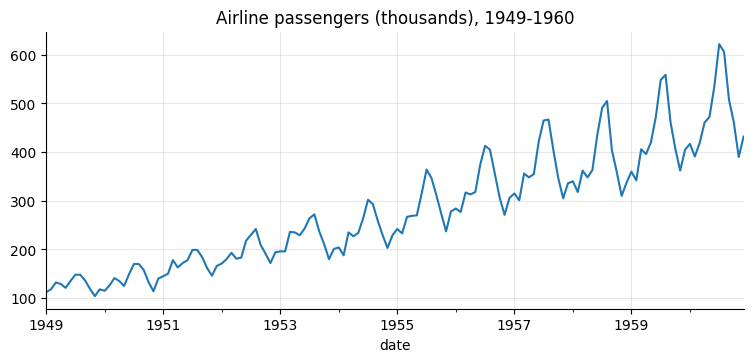

In [3]:
ax = ap.plot(title='Airline passengers (thousands), 1949-1960')
# Change to np.log(ap).plot(...) and run again

In [4]:
cpi = tsdata.nigeria_cpi(); fx = tsdata.nigeria_fx(); grid = tsdata.nigeria_grid()
pd.concat([cpi, fx, grid], axis=1).tail()

,cpi,ngn_usd,generation_mw
date,,,
2026-03-01,NaN,1378.8184,3642.5
2026-04-01,NaN,1360.7185,3500.0
2026-05-01,NaN,1369.4947,NaN
2026-06-01,NaN,1366.4902,NaN
2026-07-01,NaN,1372.7523,NaN


## Self-check (ungraded)

1. What is the seasonal period m of monthly CPI? Of daily electricity demand?
2. Write one sentence on what the CPI plot shows after mid-2023.
3. In your own words: why can you not use random k-fold cross-validation on a time series?

In [5]:
ng_cpi = tsdata.nigeria_cpi()      # Monthly CPI data (simulated); Jan 2014 - Jun 2026
print(type(ng_cpi), ng_cpi.index.freq)
print(ng_cpi.head(6))
print(ng_cpi.index[:3])

print( )
print('-' * 50)
print( )

daily_dem = tsdata.daily_demand()      # Daily Electricity Demand data (US) in GWh; 1 Jan 2022 - 22 Aug 2026
print(type(daily_dem), daily_dem.index.freq)
print(daily_dem.head(6))
print(daily_dem.index[:3])

<class 'pandas.core.series.Series'> <MonthBegin>
date
2014-01-01    20.1179
2014-02-01    20.2179
2014-03-01    20.3766
2014-04-01    20.5019
2014-05-01    20.6615
2014-06-01    20.8214
Freq: MS, Name: cpi, dtype: float64
DatetimeIndex(['2014-01-01', '2014-02-01', '2014-03-01'], dtype='datetime64[ns]', name='date', freq='MS')

--------------------------------------------------

<class 'pandas.core.series.Series'> <Day>
date
2022-01-01    1809.80
2022-01-02    1912.48
2022-01-03    2388.68
2022-01-04    2491.03
2022-01-05    2436.15
2022-01-06    2481.86
Freq: D, Name: demand_gwh, dtype: float64
DatetimeIndex(['2022-01-01', '2022-01-02', '2022-01-03'], dtype='datetime64[ns]', name='date', freq='D')


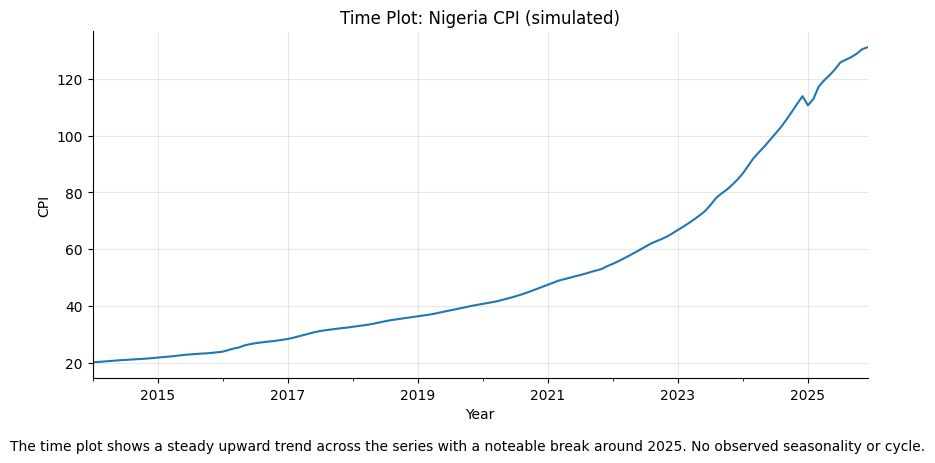

In [6]:
# Nigeria consumer Price Index Time Plot
plt.figure(figsize=(10, 4.5))
ng_cpi.plot(title = 'Time Plot: Nigeria CPI (simulated)', xlabel = 'Year', ylabel = 'CPI')

_caption = 'The time plot shows a steady upward trend across the series with a noteable break around 2025. No observed seasonality or cycle.'
plt.figtext(0.5, -0.05, _caption, wrap= True, horizontalalignment="center", fontsize = 10)
plt.show()

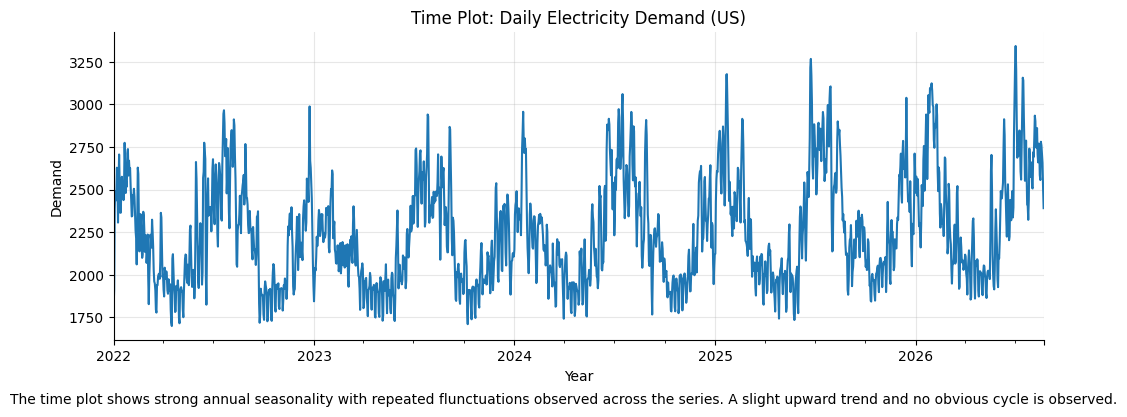

In [7]:
# Daily Electricity Demand (US) Time Plot
plt.figure(figsize=(12, 4))
daily_dem.plot(title = 'Time Plot: Daily Electricity Demand (US)', xlabel = 'Year', ylabel = 'Demand')

_caption = 'The time plot shows strong annual seasonality with repeated flunctuations observed across the series. A slight upward trend and no obvious cycle is observed.'
plt.figtext(0.5, -0.05, _caption, wrap= True, horizontalalignment="center", fontsize = 10)
plt.show()

#### Exercise 1
> Seasonal period m of CPI

The monthly CPI series shows no obvious seasonality, although its potential annual seasonal period would be (m=12) months.


> Seasonal period m of Daily Electricity Demand

Daily electricity demand reveals annual seasonality with (m=365), as well as weekly seasonality with (m=7).

#### Exercise 2

After mid-2023, the CPI level rises more rapidly, with a noticeable structural break just before 2025, suggesting a change in the series underlying behaviour.

#### Exercise 3
Random k-fold cross-validation is not suitable for time series because observations are temporally dependent, and randomly splitting them can allow future observations to be used to predict the past. This produces an unrealistic evaluation of forecasting performance.